# ANOP 330 Final Project: Bank Telemarketing

Justin Verlin and Martin Lorinkov

Scenario 4. Predicting whether a customer subscribes to a term deposit (`y`) so the call center knows who to call.

## 1. Business understanding

**Client and decision.** The client is a call-center manager at a Portuguese bank running phone campaigns for a term deposit. Before each round of calls they have to decide which customers go on the call list, and that decision comes up every campaign.

**Prediction task.** Classification. The target is `y`, whether the customer subscribed (yes = 1, no = 0). The unit of prediction is one customer contact.

**Success criteria.** The model should find more of the customers who would subscribe than calling people at random, so agents spend their time on the people most likely to say yes. We'll compare against a naive baseline that predicts "no" for everyone.

**Cost of errors (first draft).**
- False positive: we call someone who says no. Costs agent time on a call that goes nowhere.
- False negative: we skip someone who would have subscribed. Costs the deposit we never got, which is probably worth more than one wasted call.

Since a missed subscriber likely costs more than an extra call, recall on the yes class is what we care about most. We still need to put actual numbers on both costs for the spec.

## 2. Data understanding

**Source:** UCI Machine Learning Repository, Bank Marketing (Moro, Cortez and Rita, 2014), CC BY 4.0. File used: `bank-additional-full.csv` from `bank-additional.zip`. Downloaded 2026-11-19. The original file is kept unchanged.

### Load the data

The next cell downloads the zip from UCI and unzips it, so it runs in Colab without mounting Drive. If the file is already there it skips the download.

In [1]:
import os
import io
import zipfile
import urllib.request

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
csv_path = "data/bank-additional-full.csv"

if not os.path.exists(csv_path):
    os.makedirs("data", exist_ok=True)
    outer = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url).read()))
    # the csv we want is inside a second zip
    inner = zipfile.ZipFile(io.BytesIO(outer.read("bank-additional.zip")))
    with open(csv_path, "wb") as f:
        f.write(inner.read("bank-additional/bank-additional-full.csv"))
    print("downloaded")
else:
    print("already have the file")

downloaded


In [3]:
# Drive alternative: upload bank-additional-full.csv to Drive first, then run this instead of the download cell above
# from google.colab import drive
# drive.mount('/content/drive')
# csv_path = "/content/drive/MyDrive/ANOP330/bank-additional-full.csv"

In [4]:
df = pd.read_csv(csv_path, sep=";")
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### Shape and data types

In [5]:
print(df.shape)
df.dtypes

(41188, 21)


age                 int64
job                   str
marital               str
education             str
default               str
housing               str
loan                  str
contact               str
month                 str
day_of_week           str
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome              str
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                     str
dtype: object

### Data dictionary

From `bank-additional-names.txt` in the UCI download. The last column says whether the value is known before the call is made, which is what matters for leakage.

| Column | Type | Description | Known before the call? |
|---|---|---|---|
| age | numeric | Age of the customer | Yes |
| job | categorical | Type of job (admin., blue-collar, technician, ...) | Yes |
| marital | categorical | Marital status (married, single, divorced) | Yes |
| education | categorical | Education level (basic.4y, high.school, university.degree, ...) | Yes |
| default | categorical | Has credit in default? (yes/no/unknown) | Yes |
| housing | categorical | Has a housing loan? (yes/no/unknown) | Yes |
| loan | categorical | Has a personal loan? (yes/no/unknown) | Yes |
| contact | categorical | Contact type (cellular, telephone) | Yes |
| month | categorical | Month of last contact | Yes (the planned call date) |
| day_of_week | categorical | Day of week of last contact | Yes (the planned call date) |
| duration | numeric | Length of the last call in seconds | **No, leakage** |
| campaign | numeric | Number of contacts during this campaign, including the last one | Partly. Before the call it's calls so far plus this one, so the app would ask for that. Calls stop once someone says yes, so high counts lean toward no. Keep that in mind if we use it. |
| pdays | numeric | Days since last contact from a previous campaign (999 = never contacted) | Yes |
| previous | numeric | Number of contacts before this campaign | Yes |
| poutcome | categorical | Outcome of the previous campaign (failure, nonexistent, success) | Yes |
| emp.var.rate | numeric | Employment variation rate, quarterly | Yes |
| cons.price.idx | numeric | Consumer price index, monthly | Yes |
| cons.conf.idx | numeric | Consumer confidence index, monthly | Yes |
| euribor3m | numeric | Euribor 3 month rate, daily | Yes |
| nr.employed | numeric | Number of employees, quarterly | Yes |
| y | categorical | **Target.** Did the customer subscribe to a term deposit? (yes/no) | Outcome |

### Target leakage: `duration`

`duration` is how long the call lasted, which is only known after the call ends. The manager has to decide who to call before that, so the app could never ask for it. It's also tied very closely to the outcome (a 0 second call is always a no). Dropping it here so it can't end up in any model.

In [6]:
df = df.drop(columns=["duration"])
df.shape

(41188, 20)

### Missing values and 'unknown'

There are no real NaNs, but the categorical columns use the text `unknown` for missing. `pdays` uses 999 to mean the customer was never contacted before.

In [7]:
print("NaN count:", df.isna().sum().sum())

cat_cols = df.select_dtypes(exclude="number").columns
unknowns = (df[cat_cols] == "unknown").sum()
unknowns[unknowns > 0].sort_values(ascending=False)

NaN count: 0


default      8597
education    1731
housing       990
loan          990
job           330
marital        80
dtype: int64

In [8]:
print("pdays = 999:", (df["pdays"] == 999).sum(), "of", len(df))

pdays = 999: 39673 of 41188


### Class balance of y

In [9]:
counts = df["y"].value_counts()
print(counts)
print(df["y"].value_counts(normalize=True).round(3))

y
no     36548
yes     4640
Name: count, dtype: int64
y
no     0.887
yes    0.113
Name: proportion, dtype: float64


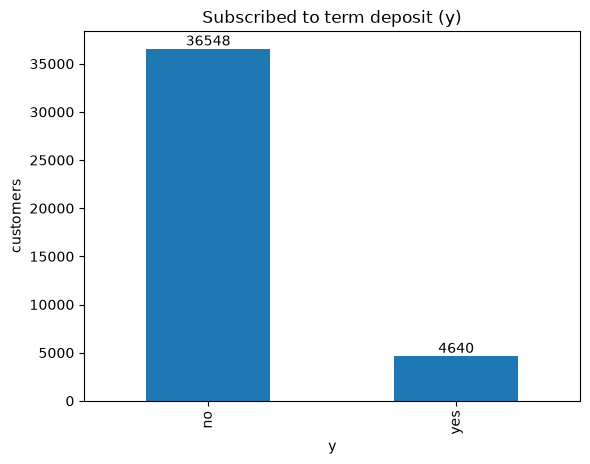

In [10]:
ax = counts.plot(kind="bar")
ax.bar_label(ax.containers[0])
plt.title("Subscribed to term deposit (y)")
plt.xlabel("y")
plt.ylabel("customers")
plt.show()

Most customers say no, so a model that predicts "no" for everyone already gets about 89% accuracy. That's why accuracy alone won't be a good metric here.

### A few distributions

In [11]:
df[["age", "campaign", "previous", "euribor3m"]].describe()

,age,campaign,previous,euribor3m
count,41188.00000,41188.000000,41188.000000,41188.000000
mean,40.02406,2.567593,0.172963,3.621291
std,10.42125,2.770014,0.494901,1.734447
min,17.00000,1.000000,0.000000,0.634000
25%,32.00000,1.000000,0.000000,1.344000
50%,38.00000,2.000000,0.000000,4.857000
75%,47.00000,3.000000,0.000000,4.961000
max,98.00000,56.000000,7.000000,5.045000


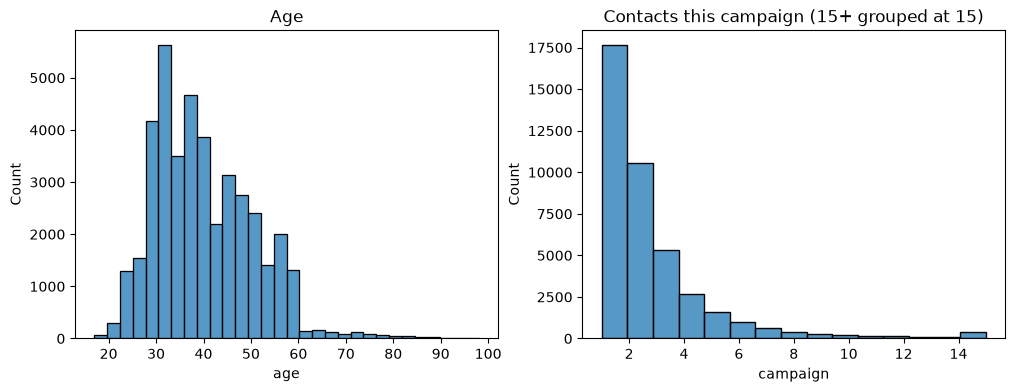

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["age"], bins=30, ax=axes[0])
axes[0].set_title("Age")
sns.histplot(df["campaign"].clip(upper=15), bins=15, ax=axes[1])
axes[1].set_title("Contacts this campaign (15+ grouped at 15)")
plt.show()

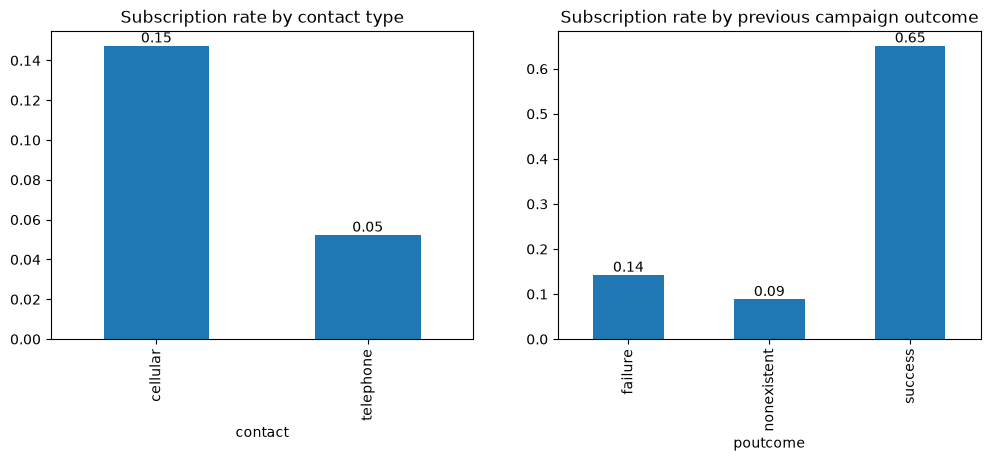

In [13]:
# subscription rate for a couple of categories
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
rate_contact = (df["y"] == "yes").groupby(df["contact"]).mean()
rate_contact.plot(kind="bar", ax=axes[0])
axes[0].bar_label(axes[0].containers[0], fmt="%.2f")
axes[0].set_title("Subscription rate by contact type")

rate_pout = (df["y"] == "yes").groupby(df["poutcome"]).mean()
rate_pout.plot(kind="bar", ax=axes[1])
axes[1].bar_label(axes[1].containers[0], fmt="%.2f")
axes[1].set_title("Subscription rate by previous campaign outcome")
plt.show()

## 3. Data preparation

TODO
- Pick 4 to 8 predictors (prefer numeric and yes/no, at most 2 categorical that need encoding)
- Code y as 1 = yes, 0 = no
- Decide what to do with `unknown` values and the `pdays` 999 code
- Encode the categorical predictors in pandas
- Train/test split before fitting any scaler or model

## 4. Modeling

TODO
- Naive baseline (DummyClassifier, most frequent class)
- Decision tree, logistic regression, logistic regression with polynomial features
- GridSearchCV on each with the same training rows, folds and scoring
- Model comparison table as a DataFrame, then pick the model to deploy

## 5. Evaluation

TODO
- Apply the selected model to the test set once and compare with the baseline
- Confusion matrix in terms of customers called and subscribers missed
- Check for overfitting (CV score vs test score)
- Save model.pkl and write requirements.txt